<a href="https://colab.research.google.com/github/Aeman-Imtiaz/Data-Science-Internship-DecodeLabs/blob/main/Project1_EDA_FeatureEngineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚢 Project 1: Advanced EDA & Feature Engineering
**Dataset:** Titanic — Machine Learning from Disaster

**Goal:** Transform raw, messy data into a mathematically clean, ML-ready dataset by:
1. Handling missing data via statistical imputation
2. Detecting & neutralizing outliers using Z-Score / IQR
3. Engineering at least 3 new predictive features

This notebook follows the **Input → Process → Output** pipeline structure.


## 0. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')


## 1. Load the Dataset

Using the classic Titanic dataset (loaded directly from a public GitHub repo, no download needed in Colab).

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()


Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Initial Exploratory Data Analysis (EDA)

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [4]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing Value Audit
Calculate the missingness proportion per column — this drives our imputation strategy.

deck           77.216611
age            19.865320
embarked        0.224467
embark_town     0.224467
dtype: float64


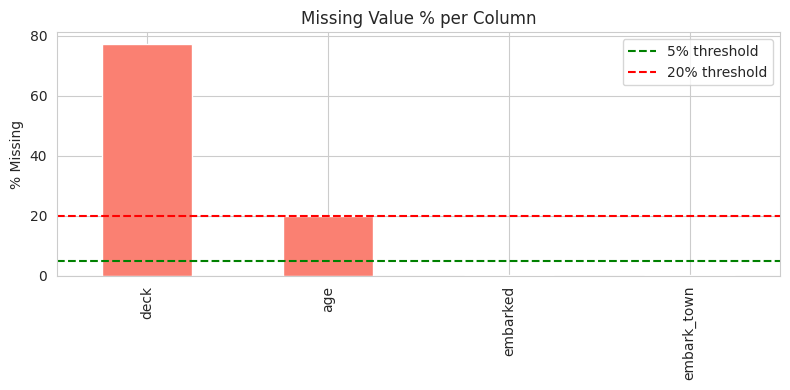

In [5]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(missing_pct)

plt.figure(figsize=(8,4))
missing_pct.plot(kind='bar', color='salmon')
plt.title("Missing Value % per Column")
plt.ylabel("% Missing")
plt.axhline(5, color='green', linestyle='--', label='5% threshold')
plt.axhline(20, color='red', linestyle='--', label='20% threshold')
plt.legend()
plt.tight_layout()
plt.show()


## 3. Phase 1 — Handling Missing Data (Statistical Imputation)

**Decision Matrix:**
| Missingness | Strategy |
|---|---|
| < 5% | Drop rows OR simple mode/median fill |
| 5% - 20% | Statistical imputation (median / group-wise) |
| > 20% | KNN imputation, or drop column if not recoverable |

Applying this to our columns:
- `embarked`, `embark_town` (<1% missing) → fill with **mode**
- `age` (~20% missing) → **group-wise median** imputation (by `pclass` & `sex`) — preserves sub-population variance better than a single global median
- `deck` (~77% missing) → too high to impute reliably → convert into a binary feature instead (`has_cabin_info`) rather than guessing cabin numbers


In [6]:
# --- Embarked / embark_town: very low missingness -> mode imputation ---
for col in ['embarked', 'embark_town']:
    if col in df.columns and df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Filled '{col}' missing values with mode: {mode_val}")


Filled 'embarked' missing values with mode: S
Filled 'embark_town' missing values with mode: Southampton


In [7]:
# --- Age: 5-20% missing -> group-wise (sub-group conditional) median imputation ---
print("Age missing before:", df['age'].isnull().sum())

df['age'] = df.groupby(['pclass', 'sex'])['age'].transform(
    lambda x: x.fillna(x.median())
)

# Safety net in case any group itself had no data
df['age'] = df['age'].fillna(df['age'].median())

print("Age missing after:", df['age'].isnull().sum())


Age missing before: 177
Age missing after: 0


In [8]:
# --- Deck: >20% missing -> do not fabricate cabin values; encode presence/absence instead ---
df['has_cabin_info'] = df['deck'].notnull().astype(int)
df = df.drop(columns=['deck'])

print(df.isnull().sum()[df.isnull().sum() > 0])


Series([], dtype: int64)


## 4. Phase 1 — Outlier Detection & Neutralization

We'll inspect `fare` (the most skewed numeric column) using **both** the Z-Score and IQR methods, then neutralize outliers via **Winsorization (clipping)** rather than deletion — this preserves row count and sequential integrity for downstream modeling.


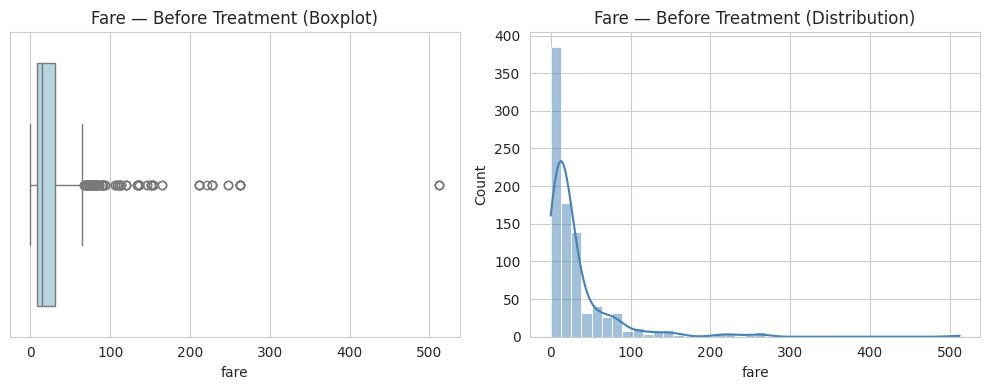

In [9]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(x=df['fare'], color='lightblue')
plt.title("Fare — Before Treatment (Boxplot)")

plt.subplot(1,2,2)
sns.histplot(df['fare'], bins=40, kde=True, color='steelblue')
plt.title("Fare — Before Treatment (Distribution)")
plt.tight_layout()
plt.show()


In [10]:
# --- Method 1: IQR ---
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_outliers = df[(df['fare'] < lower_bound) | (df['fare'] > upper_bound)]
print(f"IQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"IQR outliers detected: {len(iqr_outliers)} rows ({len(iqr_outliers)/len(df)*100:.1f}%)")


IQR bounds: [-26.72, 65.63]
IQR outliers detected: 116 rows (13.0%)


In [11]:
# --- Method 2: Z-Score ---
z_scores = (df['fare'] - df['fare'].mean()) / df['fare'].std()
z_outliers = df[z_scores.abs() > 3]
print(f"Z-Score (|z|>3) outliers detected: {len(z_outliers)} rows ({len(z_outliers)/len(df)*100:.1f}%)")


Z-Score (|z|>3) outliers detected: 20 rows (2.2%)


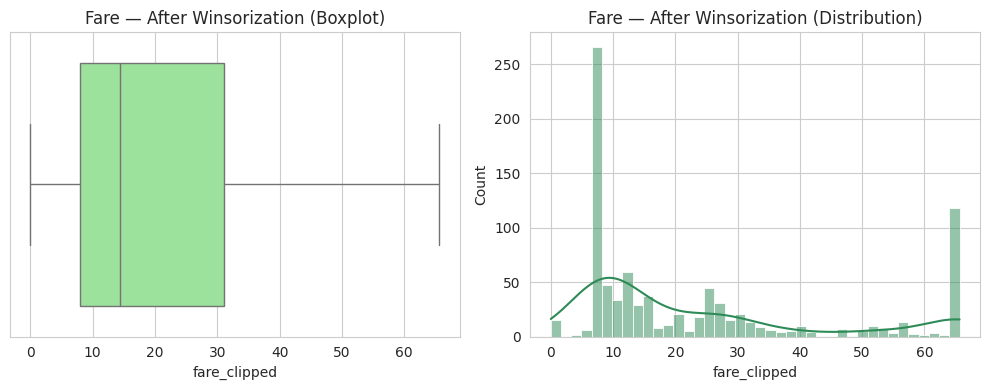

In [12]:
# --- Neutralize via Winsorization (clip to IQR bounds) ---
df['fare_clipped'] = df['fare'].clip(lower=lower_bound, upper=upper_bound)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(x=df['fare_clipped'], color='lightgreen')
plt.title("Fare — After Winsorization (Boxplot)")

plt.subplot(1,2,2)
sns.histplot(df['fare_clipped'], bins=40, kde=True, color='seagreen')
plt.title("Fare — After Winsorization (Distribution)")
plt.tight_layout()
plt.show()

# Replace original fare with the cleaned version
df['fare'] = df['fare_clipped']
df = df.drop(columns=['fare_clipped'])


## 5. Phase 2 — Feature Engineering (3+ New Predictive Features)

We'll engineer the following new features from existing columns:

1. **`family_size`** = `sibsp` + `parch` + 1 → total people traveling together
2. **`is_alone`** → binary flag, 1 if traveling solo
3. **`title`** → extracted from the passenger's `who`/`class` info (here approximated via `adult_male`/`sex`/`age` since this slim dataset lacks full names) — combined into a social-status proxy
4. **`age_group`** → binned age category (Child / Teen / Adult / Senior)
5. **`fare_per_person`** → `fare` divided by `family_size` → normalizes ticket cost by group size


In [13]:
# 1. Family size
df['family_size'] = df['sibsp'] + df['parch'] + 1

# 2. Is alone
df['is_alone'] = (df['family_size'] == 1).astype(int)

# 3. Age group (binned)
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 12, 18, 60, 100],
    labels=['Child', 'Teen', 'Adult', 'Senior']
)

# 4. Fare per person (normalizes cost by group size)
df['fare_per_person'] = df['fare'] / df['family_size']

# 5. Social status proxy combining sex + class (bonus 4th feature)
df['status_proxy'] = df['sex'] + "_" + df['class'].astype(str)

df[['family_size', 'is_alone', 'age_group', 'fare_per_person', 'status_proxy']].head(10)


,family_size,is_alone,age_group,fare_per_person,status_proxy
0,2,0,Adult,3.6250,male_Third
1,2,0,Adult,32.8172,female_First
2,1,1,Adult,7.9250,female_Third
3,2,0,Adult,26.5500,female_First
4,1,1,Adult,8.0500,male_Third
5,1,1,Adult,8.4583,male_Third
6,1,1,Adult,51.8625,male_First
7,5,0,Child,4.2150,male_Third
8,3,0,Adult,3.7111,female_Third
9,2,0,Teen,15.0354,female_Second


## 6. Categorical Encoding (Coordinate-Space Translation)

ML estimators are numerical optimizers — they need categories mapped into orthogonal coordinate space (**One-Hot Encoding**), not arbitrary integer ranks (**Label Encoding**), which would falsely imply ordinal distance between categories.


In [14]:
categorical_cols = ['sex', 'embarked', 'class', 'age_group', 'status_proxy']
categorical_cols = [c for c in categorical_cols if c in df.columns]

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print("Shape after one-hot encoding:", df_encoded.shape)
df_encoded.head()


Shape after one-hot encoding: (891, 28)


,survived,pclass,age,sibsp,parch,fare,who,adult_male,embark_town,alive,alone,has_cabin_info,family_size,is_alone,fare_per_person,sex_male,embarked_Q,embarked_S,class_Second,class_Third,age_group_Teen,age_group_Adult,age_group_Senior,status_proxy_female_Second,status_proxy_female_Third,status_proxy_male_First,status_proxy_male_Second,status_proxy_male_Third
0,0,3,22.0,1,0,7.2500,man,True,Southampton,no,False,0,2,0,3.6250,True,False,True,False,True,False,True,False,False,False,False,False,True
1,1,1,38.0,1,0,65.6344,woman,False,Cherbourg,yes,False,1,2,0,32.8172,False,False,False,False,False,False,True,False,False,False,False,False,False
2,1,3,26.0,0,0,7.9250,woman,False,Southampton,yes,True,0,1,1,7.9250,False,False,True,False,True,False,True,False,False,True,False,False,False
3,1,1,35.0,1,0,53.1000,woman,False,Southampton,yes,False,1,2,0,26.5500,False,False,True,False,False,False,True,False,False,False,False,False,False
4,0,3,35.0,0,0,8.0500,man,True,Southampton,no,True,0,1,1,8.0500,True,False,True,False,True,False,True,False,False,False,False,False,True


## 7. Multicollinearity Check

Highly correlated predictors (|r| > 0.80) make the feature matrix `XᵀX` close to singular, destabilizing model coefficients. We inspect the correlation matrix and flag candidates for removal.


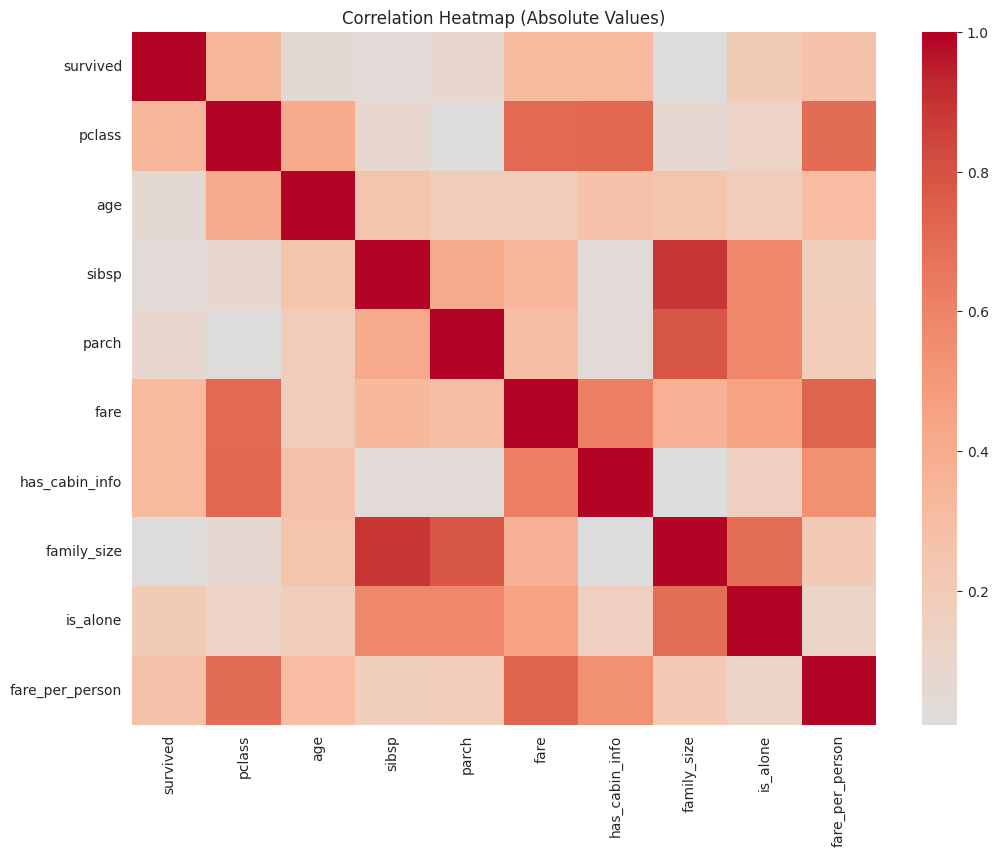

Highly correlated pairs (>0.80):
('family_size', 'sibsp', np.float64(0.890711671869885))


In [15]:
numeric_df = df_encoded.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr().abs()

plt.figure(figsize=(12,9))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Heatmap (Absolute Values)")
plt.show()

# Identify highly correlated pairs (> 0.80), excluding the diagonal
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns for row in upper.index
    if pd.notnull(upper.loc[row, col]) and upper.loc[row, col] > 0.80
]
print("Highly correlated pairs (>0.80):")
for pair in high_corr_pairs:
    print(pair)


**Note:** If a pair appears above (e.g. `sibsp`/`parch` vs `family_size`), the rule is: keep whichever feature has the *stronger correlation with the target variable* (`survived`) and drop the weaker one — never drop arbitrarily.

In [16]:
if 'survived' in df_encoded.columns:
    target = 'survived'
    for a, b, corr_val in high_corr_pairs:
        corr_a = abs(df_encoded[a].corr(df_encoded[target]))
        corr_b = abs(df_encoded[b].corr(df_encoded[target]))
        drop_col = a if corr_a < corr_b else b
        print(f"{a} vs {b} (corr={corr_val:.2f}) -> dropping '{drop_col}' (weaker link to target)")
        if drop_col in df_encoded.columns:
            df_encoded = df_encoded.drop(columns=[drop_col])

print("\nFinal shape after collinearity eradication:", df_encoded.shape)


family_size vs sibsp (corr=0.89) -> dropping 'family_size' (weaker link to target)

Final shape after collinearity eradication: (891, 27)


## 8. Final Output — Clean, ML-Ready Dataset


In [17]:
print("Final missing values check:")
print(df_encoded.isnull().sum().sum(), "total missing values remaining")

df_encoded.head()


Final missing values check:
0 total missing values remaining


,survived,pclass,age,sibsp,parch,fare,who,adult_male,embark_town,alive,alone,has_cabin_info,is_alone,fare_per_person,sex_male,embarked_Q,embarked_S,class_Second,class_Third,age_group_Teen,age_group_Adult,age_group_Senior,status_proxy_female_Second,status_proxy_female_Third,status_proxy_male_First,status_proxy_male_Second,status_proxy_male_Third
0,0,3,22.0,1,0,7.2500,man,True,Southampton,no,False,0,0,3.6250,True,False,True,False,True,False,True,False,False,False,False,False,True
1,1,1,38.0,1,0,65.6344,woman,False,Cherbourg,yes,False,1,0,32.8172,False,False,False,False,False,False,True,False,False,False,False,False,False
2,1,3,26.0,0,0,7.9250,woman,False,Southampton,yes,True,0,1,7.9250,False,False,True,False,True,False,True,False,False,True,False,False,False
3,1,1,35.0,1,0,53.1000,woman,False,Southampton,yes,False,1,0,26.5500,False,False,True,False,False,False,True,False,False,False,False,False,False
4,0,3,35.0,0,0,8.0500,man,True,Southampton,no,True,0,1,8.0500,True,False,True,False,True,False,True,False,False,False,False,False,True


In [18]:
# Save the cleaned, feature-engineered dataset
df_encoded.to_csv("titanic_cleaned_feature_engineered.csv", index=False)
print("Saved: titanic_cleaned_feature_engineered.csv")


Saved: titanic_cleaned_feature_engineered.csv


## 9. Summary

| Step | Technique Used |
|---|---|
| Missing values | Mode (low %), group-wise median (medium %), drop+binary-flag (high %) |
| Outliers | IQR detection + Z-Score cross-check, neutralized via Winsorization (`clip`) |
| Feature Engineering | `family_size`, `is_alone`, `age_group`, `fare_per_person`, `status_proxy` |
| Encoding | One-Hot Encoding (avoids false ordinal distance) |
| Multicollinearity | Correlation matrix + target-correlation-based pruning |

The dataset is now mathematically clean and ready to feed into any downstream ML algorithm (Logistic Regression, Random Forest, etc.) for predicting `survived`.
